# 横断面の状態変数と、その予測力

**目的**: クロスセクショナルなスコア（`comp_ew` など）は毎月同じ重みで使っている。市場全体の「状態」（横断面の散らばり、
銘柄間の相関、ブレス、サイズサイクル、流動性、バリュエーション、IPO 活動）を月次の時系列として作り、

1. 市場（時価加重）と サイズサイクル（等ウェイト − 時価加重）を予測できるか
2. ファクターのロングショート（Q5−Q1）の成績や `comp_ew` の IC が、状態によって変わるか

を調べる。時系列の情報をクロスセクショナルなスコアの重み付けやリスク管理に使う入口を探すのが狙い。

**仮説 / 予測**（文献とインド市場の観察から、データを見る前に置いたもの）

| 仮説 | 予測 |
| --- | --- |
| H1 分散が高いと銘柄間の差がつきやすい（Stivers & Sun 2010 ほか） | 横断面 SD が高い月の翌月は Q5−Q1 の絶対値と IC が大きい |
| H2 相関が高い・ブレスが低い局面は「マクロで一斉に動く」 | モメンタムと `comp_ew` が弱い（弱気局面モメンタムの結果と整合） |
| H3 小型優位のサイズサイクル（EW−CW が高い）はリスクオン | バリュー・低品質・高ボラが強く、低ボラ・クオリティが弱い |
| H4 流動性ショック・高バリュエーション・IPO の多さは過熱の印 | 市場の将来リターンが低い（Baker–Wurgler 型） |
| H5 横断面のバリュエーション・スプレッド（BP 上位 / 下位）が広いとバリューの期待リターンが高い（Asness ほか「value spread」） | 広い月の翌月は `bp_act` の Q5−Q1 が高い |

**設計**

- 状態変数は月末 $t$ に確定する情報だけで作る（日次は月 $t$ の最終営業日まで）。構成銘柄は月末 $t$ のユニバース。
- 市場の予測: 翌 1・3・12 か月の累積対数リターン（`cw_imi`、配当込み月次）と、EW−CW の累積対数スプレッド。
  単回帰（状態は全期間で標準化して係数を「1 SD あたり」に揃える）、Newey–West t 値（ラグ = $h$）。
  サンプル外 R² は拡大窓（最初の 60 か月で推定開始、時点 $t$ で目的変数が確定しているデータだけで推定）、ベンチマークは過去平均。
- ファクター: 各月ユニバース内で、スコア上位 20%（Q5）と下位 20%（Q1）の等ウェイト翌月 `drtn` の差。
  向きは「プレミアムが期待される側を Q5」に揃える（`vola60`・`mv`・`ta_grw` は符号反転）。`mom1` は素の向き（Q5 = 直近の勝ち組）なので、負なら短期リバーサル。
- 条件付き成績: 月末 $t$ の状態の三分位（判定の閾値はそれまでの拡大窓の 1/3・2/3 分位、最低 36 か月）で $t+1$ のファクターリターンを分ける。
  あわせて、翌月のファクターリターンを標準化した状態に回帰した NW t 値（ラグ 3）を IS（2008〜2017）と OOS（2018〜）で出す。

**規約・注意**

- 期間は 2008-01〜2026-07（予測対象は 2008-02 以降のリターン）。2007 年以前はユニバースが 26〜51 銘柄なので使わない。
- 状態 14 個 × ファクター 9 本 ≒ 126 の検定をするので、$|t| > 2$ が偶然 6 個前後出ても不思議ではない。IS と OOS の両方で同じ符号かを重視する。
- 状態変数は互いに相関が強い（ボラ・相関・分散は同じ「ストレス」の別の顔）。

In [1]:
import sys
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_market_panel import load_panel

from alphaeval import InputStore

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

START, END = "2008-01-31", "2026-07-31"
IS_END = "2017-12-31"
panel = load_panel("../../data/market_panel", fields=("ret", "close", "value"))
store = InputStore("../../input/msci_india_imi")

cap = panel.monthly["cap"]
drtn = panel.monthly["drtn"]
member_m = cap.notna()
ret_d = panel.daily["ret"]
close_d = panel.daily["close"]
value_d = panel.daily["value"]
idx_m = panel.monthly_index
idx_d = panel.daily_index
months = cap.index[(cap.index >= "2007-01-31") & (cap.index <= END)]
days = ret_d.index
last_day = pd.Series(days, index=days).groupby(days.to_period("M")).max()
last_day.index = last_day.index.to_timestamp(how="end").normalize()
print(len(months), "months;", ret_d.shape, "daily")

235 months; (5836, 1063) daily


In [2]:
def nw_tstat(
    y: np.ndarray, x: np.ndarray | None = None, lags: int = 0
) -> tuple[float, float]:
    """OLS の傾き（x が None なら平均）と Newey–West の t 値。

    Args:
        y (np.ndarray): 目的変数。
        x (np.ndarray | None): 説明変数（1 本）。None なら定数のみ。
        lags (int): NW のラグ数（Bartlett カーネル）。

    Returns:
        tuple[float, float]: 係数と t 値。

    Examples:
        >>> b, t = nw_tstat(np.array([1.0, 2.0, 3.0]), None, 0)
    """
    y = np.asarray(y, float)
    X = (
        np.ones((len(y), 1))
        if x is None
        else np.column_stack([np.ones(len(y)), np.asarray(x, float)])
    )
    ok = np.isfinite(y) & np.isfinite(X).all(axis=1)
    y, X = y[ok], X[ok]
    n, k = X.shape
    if n <= k + 2:
        return np.nan, np.nan
    xtx_inv = np.linalg.inv(X.T @ X)
    beta = xtx_inv @ X.T @ y
    u = y - X @ beta
    xu = X * u[:, None]
    s = xu.T @ xu
    for lag in range(1, lags + 1):
        w = 1 - lag / (lags + 1)
        g = xu[lag:].T @ xu[:-lag]
        s += w * (g + g.T)
    cov = xtx_inv @ s @ xtx_inv
    j = k - 1
    return beta[j], beta[j] / np.sqrt(cov[j, j])


def zscore_full(s: pd.Series) -> pd.Series:
    """全期間で標準化（係数を 1 SD あたりに揃えるためだけに使う。予測そのものには使わない）。"""
    return (s - s.mean()) / s.std()

## 1. 状態変数を作る

| 変数 | 定義（月末 $t$） | 期待する意味 |
| --- | --- | --- |
| `csd_m` | 月 $t$ の `drtn` の横断面 SD（構成銘柄、上下 1% で丸め） | 銘柄間の散らばり |
| `csd_d` | 月 $t$ の日次リターンの横断面 SD の平均 | 同上（日次） |
| `avg_corr` | 直近 63 営業日の平均ペア相関 ≈ $\mathrm{Var}(r_{EW}) / (\overline{\sigma_i})^2$ | 一斉に動く度合い |
| `rv21` / `rv63` | `cw_imi` の日次リターンの実現ボラ（年率） | 市場のストレス |
| `breadth_200` | 終値が 200 日移動平均を上回る銘柄の比率 | ブレス |
| `breadth_12m` | 過去 12 か月の `drtn` 累積が正の銘柄の比率 | 同上（月次） |
| `hl52` | 月中に 52 週高値を更新した比率 − 52 週安値を更新した比率 | 同上 |
| `size_cyc` | EW − CW（IMI）の過去 12 か月の累積対数リターン差 | サイズサイクル |
| `value_shock` | 月 $t$ の集計売買代金（日平均）/ 過去 12 か月平均 の対数 | 流動性・投機の過熱 |
| `amihud` | 銘柄の月平均 $|r|/$売買代金（10 億 INR あたり）の横断面中央値（対数） | 非流動性 |
| `agg_bp` | 時価加重の B/P（$\sum cap / \sum (cap/PBR)$ の逆数）の対数 | 市場の割安度 |
| `agg_ep` | 時価加重の E/P（PER > 0 の銘柄） | 同上 |
| `bp_spread` | BP 上位 20% の中央値 / 下位 20% の中央値 の対数 | バリュー・スプレッド |
| `new_entry` | 過去 12 か月に初めてユニバースに入った銘柄数 / 構成銘柄数（2007 年のユニバース拡大を含む 2008-10 までは欠損） | IPO・新規組入れ活動 |

In [3]:
mem_t = member_m.loc[months]
states = pd.DataFrame(index=months)

# 横断面 SD（月次）
r_in = drtn.loc[months].where(
    member_m.shift(1).loc[months].fillna(False)
)  # 月 t の構成 = 月末 t-1 のユニバース


def clipped_sd(row: pd.Series) -> float:
    x = row.dropna()
    if len(x) < 20:
        return np.nan
    lo, hi = x.quantile([0.01, 0.99])
    return x.clip(lo, hi).std()


states["csd_m"] = r_in.apply(clipped_sd, axis=1)

# 日次: 構成銘柄（月末 t-1 のユニバース → 月 t の営業日）
mem_d = panel.member_daily("cap").notna()
r_mem = ret_d.where(mem_d)
csd_daily = r_mem.std(axis=1)
csd_daily = csd_daily[r_mem.notna().sum(axis=1) >= 20]
cs = csd_daily.groupby(csd_daily.index.to_period("M")).mean()
cs.index = cs.index.to_timestamp(how="end").normalize()
states["csd_d"] = cs.reindex(months)

# 平均ペア相関（月末 t のユニバース、直近 63 営業日）
day_pos = pd.Series(np.arange(len(days)), index=days)
ret_np = ret_d.to_numpy()
col_pos = pd.Series(np.arange(ret_d.shape[1]), index=ret_d.columns)
avg_corr = {}
for m in months:
    if m not in last_day.index:
        continue
    e = day_pos[last_day[m]]
    if e < 63:
        continue
    cols = col_pos[mem_t.columns[mem_t.loc[m]].intersection(ret_d.columns)].to_numpy()
    win = ret_np[e - 62 : e + 1][:, cols]
    ok = np.isfinite(win).sum(axis=0) >= 50
    win = win[:, ok]
    sd = np.nanstd(win, axis=0, ddof=1)
    port = np.nanmean(win, axis=1)
    avg_corr[m] = np.var(port, ddof=1) / np.mean(sd) ** 2
states["avg_corr"] = pd.Series(avg_corr)

# 市場の実現ボラ
mkt_d = idx_d["cw_imi"]
for w in (21, 63):
    rv = mkt_d.rolling(w, min_periods=int(w * 0.8)).std() * np.sqrt(252)
    states[f"rv{w}"] = rv.reindex(last_day.reindex(months)).to_numpy()

# ブレス: 200 日移動平均
px = close_d.where(close_d > 0).ffill(limit=5)
ma200 = px.rolling(200, min_periods=180).mean()
above = (px > ma200).where(ma200.notna())
b200 = {}
for m in months:
    if m not in last_day.index:
        continue
    d = last_day[m]
    names = mem_t.columns[mem_t.loc[m]]
    a = above.loc[d, above.columns.intersection(names)].dropna()
    b200[m] = a.mean() if len(a) >= 20 else np.nan
states["breadth_200"] = pd.Series(b200)

# ブレス: 12 か月リターン
lr = np.log1p(drtn)
cum12 = lr.rolling(12, min_periods=12).sum()
states["breadth_12m"] = (
    (cum12 > 0).where(cum12.notna() & member_m).loc[months].mean(axis=1)
)

# 52 週高値・安値の更新
prior_max = px.shift(1).rolling(252, min_periods=200).max()
prior_min = px.shift(1).rolling(252, min_periods=200).min()
new_hi = (px >= prior_max).where(prior_max.notna()).astype(float)
new_lo = (px <= prior_min).where(prior_min.notna()).astype(float)
per = days.to_period("M")
hi_m = new_hi.groupby(per).max()
lo_m = new_lo.groupby(per).max()
hi_m.index = hi_m.index.to_timestamp(how="end").normalize()
lo_m.index = lo_m.index.to_timestamp(how="end").normalize()
mem_prev = member_m.shift(1).reindex(hi_m.index).fillna(False)  # 月 t の構成銘柄
hi_frac = hi_m.reindex(columns=member_m.columns).where(mem_prev).mean(axis=1)
lo_frac = lo_m.reindex(columns=member_m.columns).where(mem_prev).mean(axis=1)
states["hl52"] = (hi_frac - lo_frac).reindex(months)

# サイズサイクル
lev = np.log1p(idx_m["ew_imi"]) - np.log1p(idx_m["cw_imi"])
states["size_cyc"] = lev.rolling(12, min_periods=12).sum().reindex(months)

# 売買代金ショック
v_mem = value_d.where(mem_d)
agg_v = v_mem.sum(axis=1, min_count=20)
agg_vm = agg_v.groupby(agg_v.index.to_period("M")).mean()
agg_vm.index = agg_vm.index.to_timestamp(how="end").normalize()
states["value_shock"] = np.log(
    agg_vm / agg_vm.shift(1).rolling(12, min_periods=10).mean()
).reindex(months)

# Amihud
illiq = (ret_d.abs() / (value_d / 1e9)).where(mem_d & (value_d > 0))
ill_m = illiq.groupby(per).mean()
ill_m.index = ill_m.index.to_timestamp(how="end").normalize()
states["amihud"] = np.log(ill_m.median(axis=1)).reindex(months)

# バリュエーション
pbr = panel.monthly["pbr"].where(
    (panel.monthly["pbr"] > 0) & (panel.monthly["pbr"] < 1e4)
)
pe = panel.monthly["per"].where(
    (panel.monthly["per"] > 0) & (panel.monthly["per"] < 1e4)
)
c = cap.where(member_m)
states["agg_bp"] = np.log(
    (c / pbr).sum(axis=1, min_count=20) / c.where(pbr.notna()).sum(axis=1)
).reindex(months)
states["agg_ep"] = (
    (c / pe).sum(axis=1, min_count=20) / c.where(pe.notna()).sum(axis=1)
).reindex(months)
bp = (1.0 / pbr).where(member_m)


def bp_spread(row: pd.Series) -> float:
    x = row.dropna()
    if len(x) < 50:
        return np.nan
    q = x.rank(pct=True)
    return np.log(x[q >= 0.8].median() / x[q <= 0.2].median())


states["bp_spread"] = bp.loc[months].apply(bp_spread, axis=1)

# 新規組入れ（初めてユニバースに入った銘柄）
first = member_m.idxmax()[member_m.any()]
n_new = first.value_counts().reindex(cap.index, fill_value=0).sort_index()
states["new_entry"] = (n_new.rolling(12).sum() / member_m.sum(axis=1)).reindex(months)
# 2007 年のユニバース拡大（51 → 249 銘柄）は IPO ではないので、その月を含む窓（〜2008-10）は欠損にする
states.loc[states.index < "2008-11-30", "new_entry"] = np.nan

states = states.loc["2007-12-31":END].astype(float)
STATE_COLS = list(states.columns)
display(states.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
csd_m,224.0,0.097,0.023,0.061,0.084,0.092,0.103,0.277
csd_d,224.0,0.023,0.005,0.017,0.020,0.022,0.023,0.050
avg_corr,224.0,0.231,0.086,0.063,0.168,0.218,0.279,0.511
rv21,224.0,0.172,0.109,0.058,0.112,0.145,0.191,0.782
rv63,224.0,0.178,0.099,0.074,0.120,0.150,0.192,0.588
breadth_200,224.0,0.546,0.244,0.017,0.355,0.544,0.748,0.988
breadth_12m,224.0,0.575,0.239,0.009,0.427,0.545,0.771,0.993
hl52,224.0,0.079,0.280,-0.922,-0.095,0.100,0.287,0.721
size_cyc,224.0,-0.005,0.112,-0.308,-0.073,0.003,0.074,0.254
value_shock,224.0,0.062,0.199,-0.357,-0.086,0.046,0.183,0.725


## 2. 記述: 推移と相互相関

網掛けは代表的な局面（2008 世界金融危機、2011 欧州危機・ルピー安、2013 テーパー・タントラム、2018–19 中小型急落・IL&FS、2020 コロナ、2022 利上げ）。

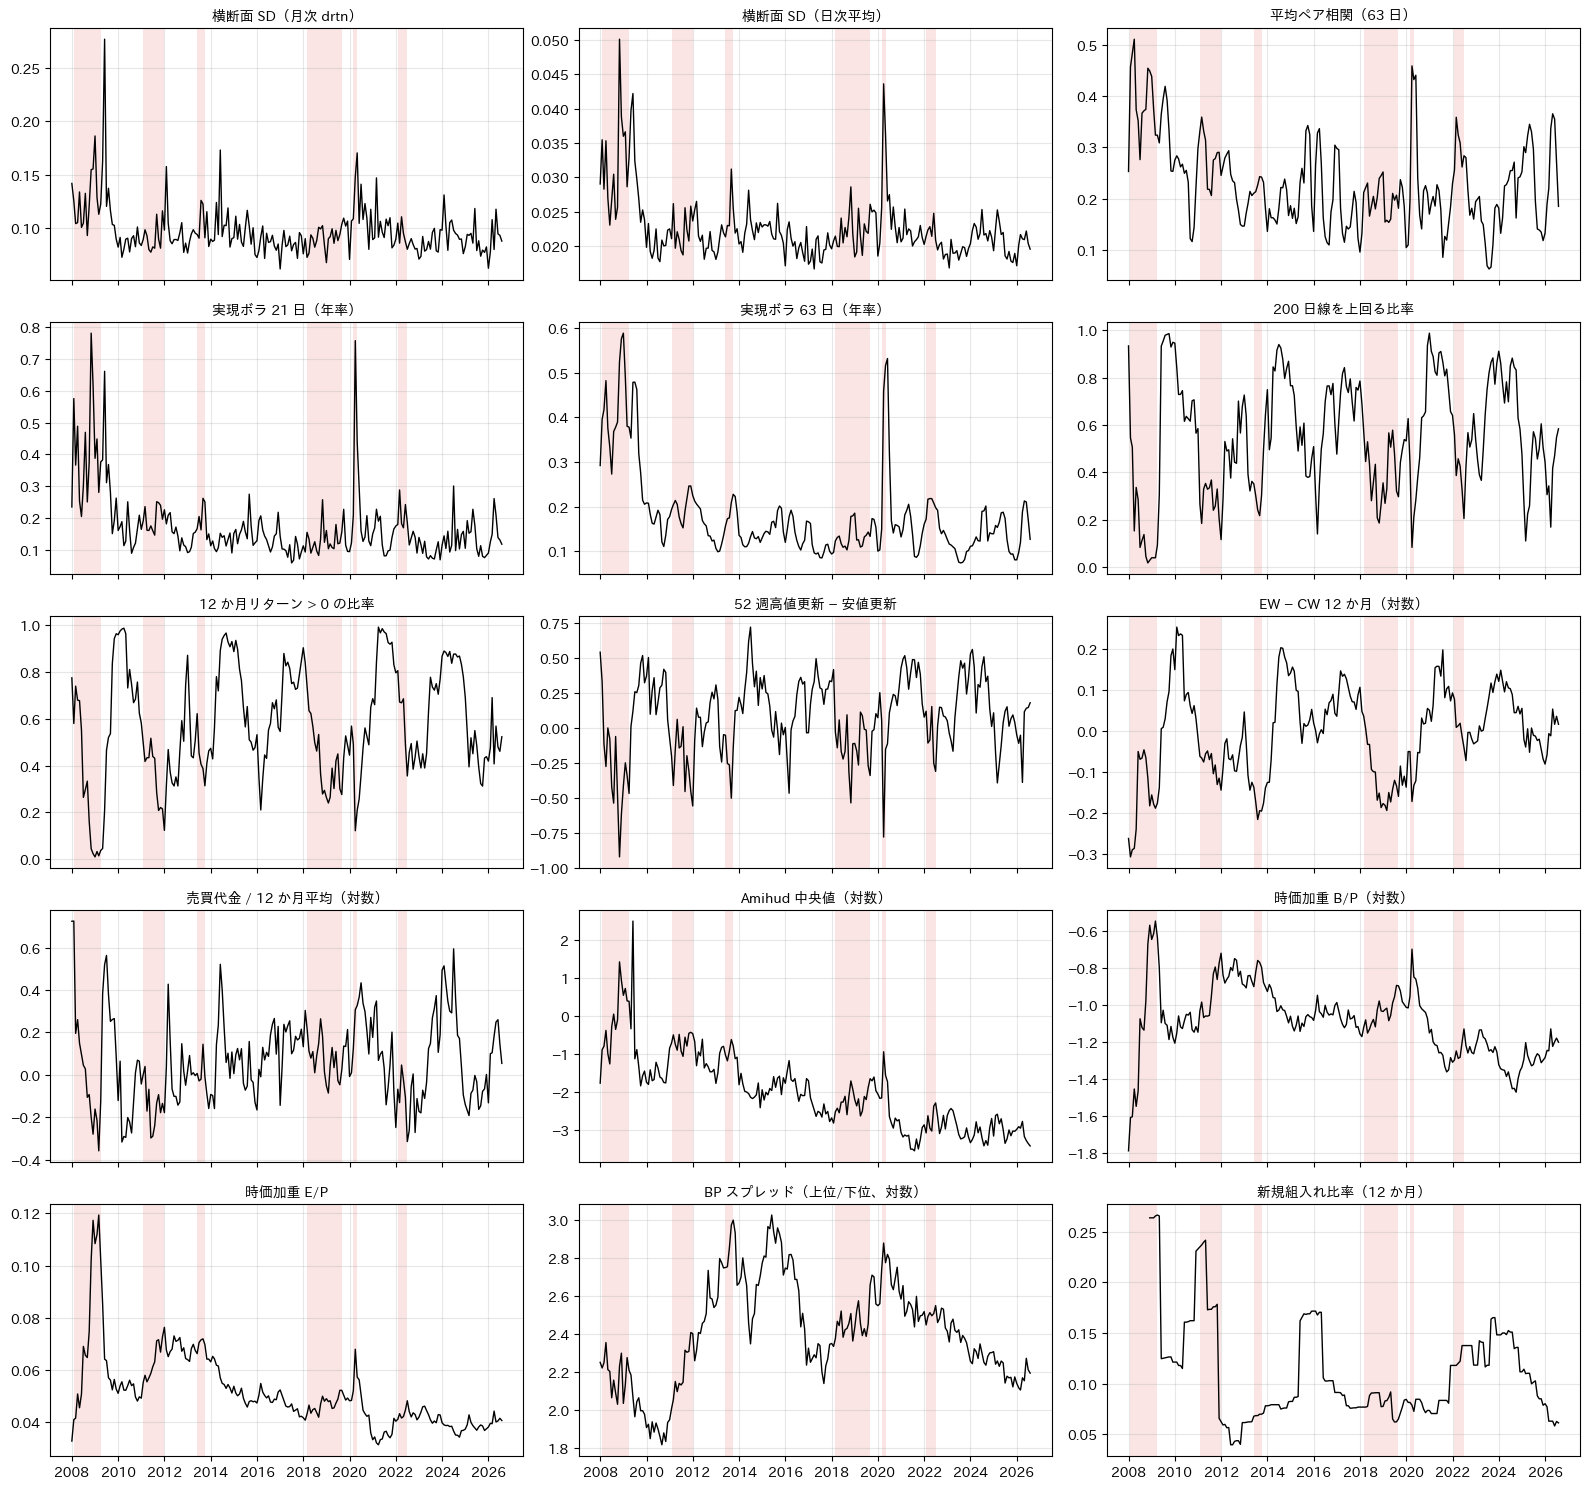

In [4]:
EPISODES = {
    "GFC": ("2008-01-31", "2009-03-31"),
    "2011": ("2011-01-31", "2011-12-31"),
    "Taper": ("2013-05-31", "2013-09-30"),
    "2018-19": ("2018-02-28", "2019-08-31"),
    "COVID": ("2020-02-29", "2020-04-30"),
    "2022": ("2022-01-31", "2022-06-30"),
}
LABELS = {
    "csd_m": "横断面 SD（月次 drtn）",
    "csd_d": "横断面 SD（日次平均）",
    "avg_corr": "平均ペア相関（63 日）",
    "rv21": "実現ボラ 21 日（年率）",
    "rv63": "実現ボラ 63 日（年率）",
    "breadth_200": "200 日線を上回る比率",
    "breadth_12m": "12 か月リターン > 0 の比率",
    "hl52": "52 週高値更新 − 安値更新",
    "size_cyc": "EW − CW 12 か月（対数）",
    "value_shock": "売買代金 / 12 か月平均（対数）",
    "amihud": "Amihud 中央値（対数）",
    "agg_bp": "時価加重 B/P（対数）",
    "agg_ep": "時価加重 E/P",
    "bp_spread": "BP スプレッド（上位/下位、対数）",
    "new_entry": "新規組入れ比率（12 か月）",
}
fig, axes = plt.subplots(5, 3, figsize=(16, 15), sharex=True)
for ax, col in zip(axes.ravel(), STATE_COLS):
    s = states[col]
    ax.plot(s.index, s, color="k", linewidth=1)
    for a, b in EPISODES.values():
        ax.axvspan(
            pd.Timestamp(a), pd.Timestamp(b), color="C3", alpha=0.12, linewidth=0
        )
    ax.set_title(LABELS[col], fontsize=10)
plt.tight_layout()
plt.show()

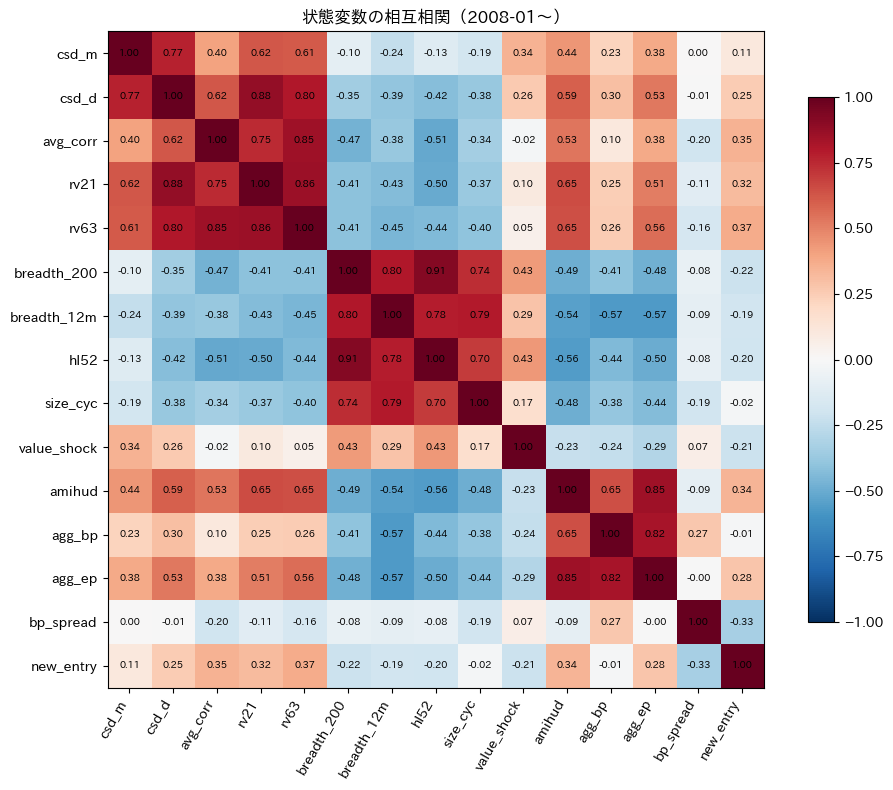

,csd_m,csd_d,avg_corr,rv21,rv63,breadth_200,breadth_12m,hl52,size_cyc,value_shock,amihud,agg_bp,agg_ep,bp_spread,new_entry
1 か月自己相関,0.44,0.69,0.82,0.65,0.91,0.87,0.91,0.75,0.93,0.76,0.9,0.94,0.95,0.95,0.94


In [5]:
corr = states.loc["2008-01-31":].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("状態変数の相互相関（2008-01〜）")
ax.grid(False)
plt.tight_layout()
plt.show()

ac = pd.Series({c: states[c].autocorr(1) for c in STATE_COLS}, name="1 か月自己相関")
display(ac.round(2).to_frame().T)

In [6]:
# 局面ごとの平均（全期間の z 値）
z = (states - states.loc["2008-01-31":].mean()) / states.loc["2008-01-31":].std()
ep_tbl = pd.DataFrame({k: z.loc[a:b].mean() for k, (a, b) in EPISODES.items()})
ep_tbl["直近 12 か月"] = z.iloc[-12:].mean()
print("局面ごとの状態変数の平均（全期間で標準化した z 値）")
display(ep_tbl.round(2))

局面ごとの状態変数の平均（全期間で標準化した z 値）


,GFC,2011,Taper,2018-19,COVID,2022,直近 12 か月
csd_m,1.22,-0.24,0.33,-0.32,1.96,-0.14,-0.48
csd_d,1.98,-0.08,0.47,-0.09,2.67,-0.06,-0.60
avg_corr,1.90,0.57,-0.04,-0.38,1.52,0.79,-0.17
rv21,2.20,0.25,0.34,-0.39,2.72,0.32,-0.38
rv63,2.48,0.25,0.10,-0.46,1.99,0.27,-0.47
breadth_200,-1.57,-1.11,-1.08,-0.64,-1.24,-0.62,-0.41
breadth_12m,-1.16,-0.93,-0.57,-0.66,-1.25,0.16,-0.47
hl52,-1.39,-1.15,-1.15,-0.75,-1.33,-0.57,-0.22
size_cyc,-1.43,-0.73,-1.63,-1.04,-1.04,0.13,-0.11
value_shock,-0.31,-1.05,-0.21,0.06,1.00,-0.81,-0.01


## 3. 市場の予測（翌 1・3・12 か月）

目的変数は `cw_imi`（市場）と EW−CW（サイズサイクル）の累積対数リターン。係数は状態 1 SD あたり（%）。
NW t 値のラグは $h$。サンプル外 R²（$R^2_{OS}$）は拡大窓・過去平均ベンチマークで、2013-01 以降の予測で評価（正なら過去平均より良い）。

In [7]:
lr_m = np.log1p(idx_m.loc["2008-01-31":END])
targets = {"市場 (CW)": lr_m["cw_imi"], "EW−CW": lr_m["ew_imi"] - lr_m["cw_imi"]}
HORIZONS = (1, 3, 12)


def fwd_sum(s: pd.Series, h: int) -> pd.Series:
    # t の行 = t+1..t+h の合計
    return s[::-1].rolling(h, min_periods=h).sum()[::-1].shift(-1)


def oos_r2(
    y: pd.Series, x: pd.Series, h: int, min_train: int = 60, start: str = "2013-01-31"
) -> float:
    df = pd.concat([y.rename("y"), x.rename("x")], axis=1).dropna()
    idx = df.index
    err_m, err_b = [], []
    for i, t in enumerate(idx):
        if t < pd.Timestamp(start):
            continue
        train = df.iloc[: max(i - h + 1, 0)]  # 目的変数が t までに確定している行だけ
        if len(train) < min_train:
            continue
        b = np.polyfit(train["x"], train["y"], 1)
        pred = b[0] * df["x"].iloc[i] + b[1]
        bench = train["y"].mean()
        err_m.append((df["y"].iloc[i] - pred) ** 2)
        err_b.append((df["y"].iloc[i] - bench) ** 2)
    return 1 - np.sum(err_m) / np.sum(err_b) if err_b else np.nan


rows = []
for tname, s in targets.items():
    for h in HORIZONS:
        y = fwd_sum(s, h)
        for col in STATE_COLS:
            x = zscore_full(states[col]).reindex(y.index)
            b, t = nw_tstat(y.to_numpy(), x.to_numpy(), lags=h)
            ok = y.notna() & x.notna()
            r2 = np.corrcoef(y[ok].to_numpy(float), x[ok].to_numpy(float))[0, 1] ** 2
            rows.append(
                {
                    "対象": tname,
                    "h": h,
                    "状態": col,
                    "係数(%/SD)": 100 * b,
                    "NW t": t,
                    "R2": r2,
                    "R2_OS": oos_r2(y, states[col], h),
                }
            )
pred_tbl = pd.DataFrame(rows)
for tname in targets:
    print(f"=== {tname}")
    t = pred_tbl[pred_tbl["対象"] == tname].pivot(
        index="状態", columns="h", values=["係数(%/SD)", "NW t", "R2_OS"]
    )
    display(t.round(2))

=== 市場 (CW)


係数(%/SD)               NW t             R2_OS            
h                 1     3      12    1     3     12    1     3     12
状態                                                                   
agg_bp          1.08  3.20  11.79  2.05  2.36  2.91 -0.05 -0.16 -0.49
agg_ep          0.51  2.01   9.28  0.76  1.00  3.11 -0.04 -0.21 -0.90
amihud         -0.21 -0.44   3.04 -0.34 -0.23  0.74 -0.01 -0.04 -0.48
avg_corr       -0.18 -0.11   0.07 -0.33 -0.07  0.01 -0.04 -0.05 -0.05
bp_spread       0.55  1.25   3.90  1.22  1.09  1.10 -0.00  0.00 -0.10
breadth_12m    -0.22 -0.73  -7.61 -0.38 -0.45 -2.58 -0.01 -0.06 -0.20
breadth_200     0.33  0.99  -2.87  0.57  0.60 -1.06 -0.01 -0.01 -0.09
csd_d           0.77  1.58   5.06  1.11  0.98  1.29  0.00  0.01 -0.07
csd_m           0.39  1.60   5.42  0.82  1.62  2.42 -0.01  0.02 -0.03
hl52            0.13  0.56  -3.52  0.23  0.42 -1.38 -0.01 -0.02 -0.17
new_entry       0.36  1.03   1.74  0.55  0.56  0.33 -0.01 -0.03 -0.01
rv21            0.28  0.14   3.71  0.41  0.08  0.85 -0.01 -0.02 -0.02
rv63            0.01  0.34   4.51  0.02  0.17  0.95 -0.01 -0.02 -0.05
size_cyc        0.34  0.93  -0.48  0.83  0.76 -0.11  0.00  0.01 -0.03
value_shock     0.84  1.33  -1.08  2.09  1.24 -0.29  0.02  0.02 -0.21

=== EW−CW


係数(%/SD)              NW t             R2_OS            
h                 1     3     12    1     3     12    1     3     12
状態                                                                  
agg_bp          0.03  0.53  2.66  0.15  0.94  1.29 -0.01 -0.02 -0.12
agg_ep         -0.01  0.37  2.87 -0.02  0.51  1.50 -0.01 -0.06 -0.35
amihud         -0.13 -0.09  1.47 -0.57 -0.13  0.78 -0.01 -0.06 -0.49
avg_corr        0.12  0.43  1.47  0.55  0.82  0.90 -0.01 -0.03 -0.15
bp_spread       0.19  0.55  3.18  0.96  1.14  2.15 -0.01 -0.05  0.01
breadth_12m     0.03 -0.22 -3.21  0.14 -0.40 -2.09 -0.01 -0.03 -0.11
breadth_200     0.27  0.30 -1.42  1.30  0.59 -1.16  0.00 -0.01 -0.10
csd_d           0.21  0.74  3.00  0.76  1.25  2.18 -0.01 -0.03 -0.16
csd_m           0.14  0.77  2.88  0.60  1.91  2.93 -0.01 -0.00 -0.08
hl52            0.21  0.11 -1.61  1.07  0.25 -1.33 -0.00 -0.01 -0.16
new_entry       0.21  0.54  2.66  0.70  0.80  1.18 -0.01 -0.03  0.05
rv21            0.12  0.42  2.56  0.56  0.76  1.78 -0.01 -0.02 -0.12
rv63            0.15  0.51  3.09  0.57  0.80  2.06 -0.00 -0.03 -0.17
size_cyc        0.12  0.32 -0.78  0.65  0.74 -0.46 -0.00 -0.01 -0.08
value_shock     0.43  0.74 -0.34  2.36  2.00 -0.23  0.02  0.03 -0.05

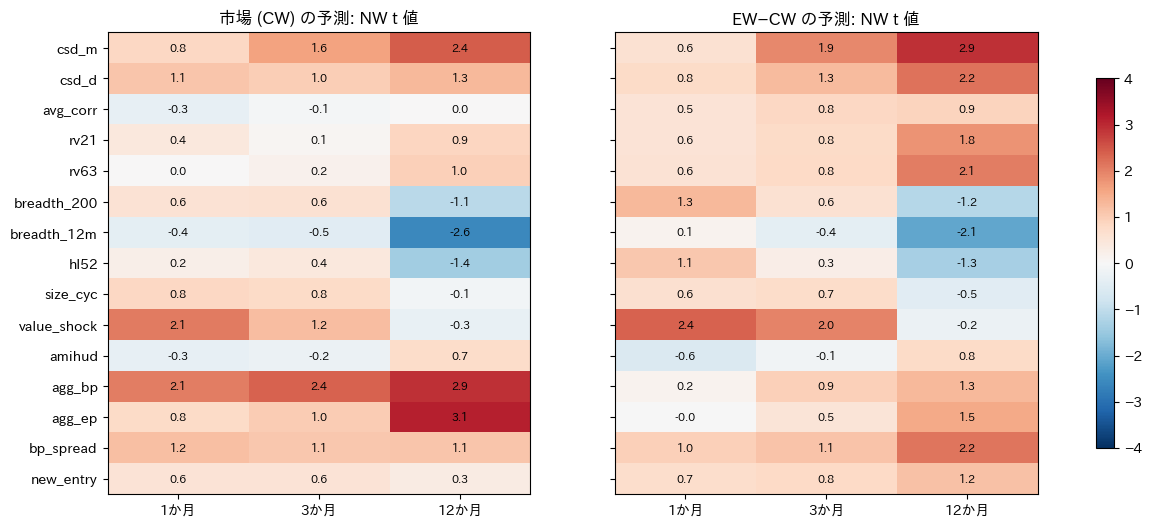

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, tname in zip(axes, targets):
    t = (
        pred_tbl[pred_tbl["対象"] == tname]
        .pivot(index="状態", columns="h", values="NW t")
        .reindex(STATE_COLS)
    )
    im = ax.imshow(t, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
    ax.set_xticks(range(len(t.columns)), [f"{h}か月" for h in t.columns])
    ax.set_yticks(range(len(t)), t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{tname} の予測: NW t 値")
    ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### 3.1 予測の IS / OOS

1 か月先について、2008〜2017（IS）と 2018〜（OOS）に分けて傾きの NW t 値を比べる（同じ符号で残るか）。

In [9]:
rows = []
for tname, s in targets.items():
    y = fwd_sum(s, 1)
    for col in STATE_COLS:
        x = zscore_full(states[col]).reindex(y.index)
        r = {"対象": tname, "状態": col}
        for lab, (a, b) in {
            "IS": ("2008-01-31", IS_END),
            "OOS": ("2018-01-31", END),
        }.items():
            bb, tt = nw_tstat(y.loc[a:b].to_numpy(), x.loc[a:b].to_numpy(), lags=1)
            r[f"{lab} 係数"] = 100 * bb
            r[f"{lab} t"] = tt
        rows.append(r)
split1 = pd.DataFrame(rows).set_index(["対象", "状態"])
display(split1.round(2))

IS 係数  IS t  OOS 係数  OOS t
対象      状態                                     
市場 (CW) csd_m         0.34  0.59    0.60   0.99
        csd_d         0.69  0.78    1.16   2.11
        avg_corr     -0.85 -1.17    0.96   1.82
        rv21         -0.11 -0.14    1.38   3.14
        rv63         -0.50 -0.59    1.54   2.48
        breadth_200   0.48  0.57    0.06   0.11
        breadth_12m  -0.16 -0.18   -0.35  -0.71
        hl52          0.50  0.64   -0.46  -0.84
        size_cyc      0.25  0.44    0.54   1.09
        value_shock   0.93  1.50    0.71   1.54
        amihud       -0.35 -0.35    0.36   0.36
        agg_bp        1.93  2.44    0.67   0.91
        agg_ep        0.93  1.01    0.99   0.67
        bp_spread     0.38  0.78    1.26   1.34
        new_entry     0.27  0.36    0.59   0.80
EW−CW   csd_m         0.32  1.08   -0.38  -1.17
        csd_d         0.30  0.85   -0.05  -0.19
        avg_corr     -0.01 -0.03    0.32   1.07
        rv21          0.04  0.13    0.33   1.35
        rv63          0.02  0.07    0.48   2.27
        breadth_200   0.31  1.04    0.21   0.84
        breadth_12m  -0.02 -0.05    0.12   0.53
        hl52          0.27  0.97    0.12   0.50
        size_cyc      0.07  0.29    0.22   0.80
        value_shock   0.42  1.51    0.47   2.11
        amihud       -0.24 -0.69   -0.41  -0.88
        agg_bp        0.13  0.47   -0.16  -0.51
        agg_ep        0.03  0.09   -0.55  -0.88
        bp_spread     0.20  0.90    0.16   0.37
        new_entry     0.18  0.51    0.26   0.73

## 4. ファクターの条件付き成績

各月ユニバース内の等ウェイト Q5−Q1（翌月 `drtn`）。向きは下表。`comp_ew` は IC（Spearman）と、ロングオンリーの代理として Q5 − ユニバース等ウェイトも見る。

In [10]:
FACTORS = {
    "comp_ew": ("composite/comp_ew", 1),
    "mom12_1": ("core/mom12_1", 1),
    "mom1": ("core/mom1", 1),
    "bp_act": ("core/bp_act", 1),
    "roe_act": ("core/roe_act", 1),
    "lowvol": ("core/vola60", -1),
    "small": ("core/mv", -1),
    "lowinv": ("core/ta_grw", -1),
}
fwd = drtn.shift(-1)  # 行 t = 月 t+1 のリターン
spread, ic = {}, {}
q5_ex = None
for name, (path, sign) in FACTORS.items():
    sc = sign * store.alpha(path, 200712, 202607).reindex(
        index=months, columns=member_m.columns
    )
    sc = sc.where(member_m.loc[months])
    r = fwd.reindex(index=months, columns=member_m.columns)
    ok = sc.notna() & r.notna()
    sc, r = sc.where(ok), r.where(ok)
    n = ok.sum(axis=1)
    p = (sc.rank(axis=1) - 0.5).div(n, axis=0)
    q5 = r.where(p >= 0.8).mean(axis=1)
    q1 = r.where(p < 0.2).mean(axis=1)
    spread[name] = (q5 - q1).where(n >= 50)
    if name == "comp_ew":
        q5_ex = (q5 - r.mean(axis=1)).where(n >= 50)
        ic[name] = sc.rank(axis=1).corrwith(r.rank(axis=1), axis=1).where(n >= 50)
F = pd.DataFrame(spread)
F["comp_ew_Q5ex"] = q5_ex
F["comp_ew_IC"] = ic["comp_ew"]
F = F.loc["2007-12-31":"2026-06-30"]  # 行 t = t+1 のリターン（2026-07 のリターンまで）
FAC_COLS = list(F.columns)

summ = pd.DataFrame(
    {
        "月平均(%)": 100 * F.mean(),
        "t": F.mean() / F.std() * np.sqrt(F.count()),
        "IS 月平均": 100 * F.loc[:IS_END].mean(),
        "OOS 月平均": 100 * F.loc["2018-01-31":].mean(),
        "月数": F.count(),
    }
)
summ.loc["comp_ew_IC", ["月平均(%)", "IS 月平均", "OOS 月平均"]] /= 100
print(
    "無条件の成績（行 t は月末 t のスコア → t+1 のリターン。IC の行は % ではなく素の値）"
)
display(summ.round(3))

無条件の成績（行 t は月末 t のスコア → t+1 のリターン。IC の行は % ではなく素の値）


,月平均(%),t,IS 月平均,OOS 月平均,月数
comp_ew,1.476,4.697,1.570,1.364,222
mom12_1,0.600,1.327,-0.086,1.414,223
mom1,-0.215,-0.665,0.145,-0.643,223
bp_act,0.246,0.596,0.349,0.123,223
roe_act,0.637,2.074,1.084,0.108,223
lowvol,0.565,1.191,1.057,-0.019,223
small,-0.022,-0.063,-0.063,0.027,223
lowinv,0.502,2.722,0.728,0.233,223
comp_ew_Q5ex,0.824,5.820,0.909,0.725,222
comp_ew_IC,0.064,7.080,0.075,0.051,222


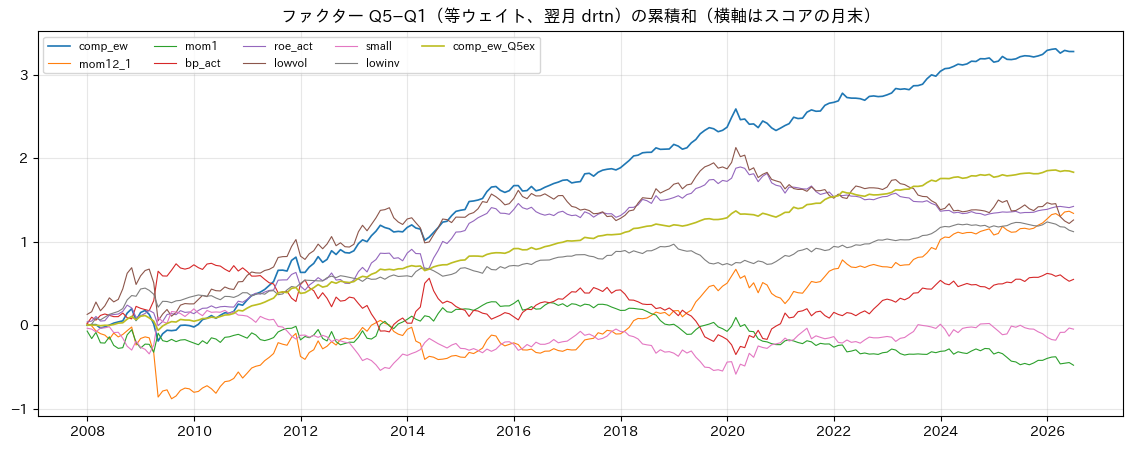

In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
for c in [c for c in FAC_COLS if c not in ("comp_ew_IC",)]:
    ax.plot(
        F.index,
        F[c].fillna(0).cumsum(),
        label=c,
        linewidth=1.2 if c.startswith("comp") else 0.8,
    )
ax.legend(ncol=5, fontsize=8)
ax.set_title("ファクター Q5−Q1（等ウェイト、翌月 drtn）の累積和（横軸はスコアの月末）")
plt.show()

### 4.1 状態の三分位ごとの平均

三分位の閾値は月末 $t$ までの拡大窓で決める（最低 36 か月、それ以前は判定なし）。表は「高 − 低」の差の t 値（Welch）。

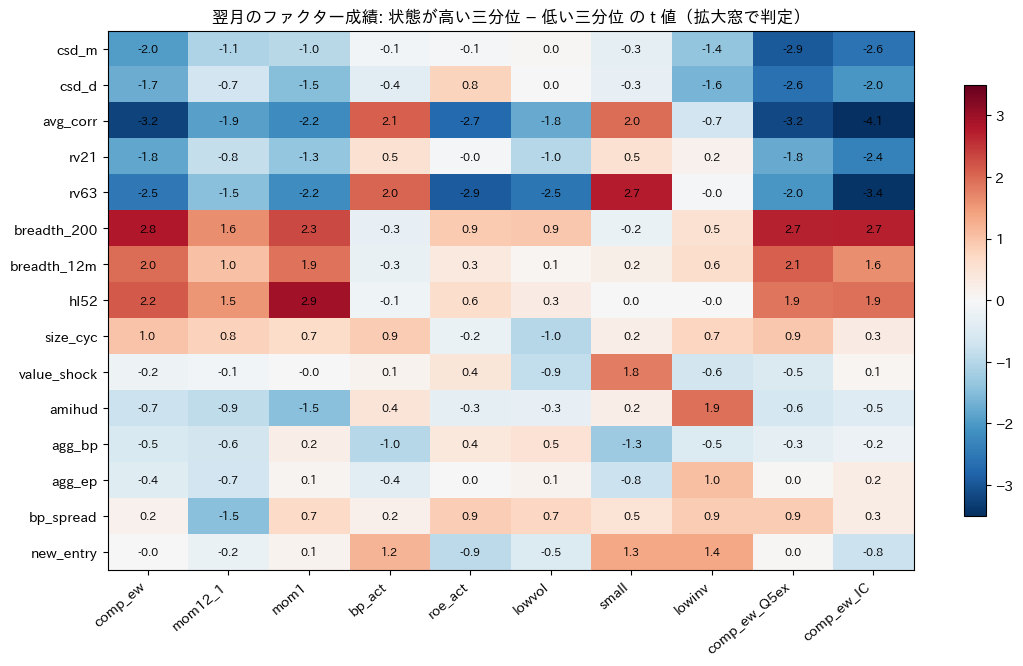

|t| > 2 の組: 26 / 150


In [12]:
def expanding_tercile(s: pd.Series, min_periods: int = 36) -> pd.Series:
    out = pd.Series(np.nan, index=s.index)
    vals = s.to_numpy()
    for i in range(len(s)):
        hist = vals[: i + 1]
        hist = hist[np.isfinite(hist)]
        if len(hist) < min_periods or not np.isfinite(vals[i]):
            continue
        lo, hi = np.quantile(hist, [1 / 3, 2 / 3])
        out.iloc[i] = 0 if vals[i] <= lo else (2 if vals[i] > hi else 1)
    return out


terc = pd.DataFrame({c: expanding_tercile(states[c]) for c in STATE_COLS})


def welch_t(a: pd.Series, b: pd.Series) -> float:
    a, b = a.dropna(), b.dropna()
    if len(a) < 5 or len(b) < 5:
        return np.nan
    return stats.ttest_ind(a, b, equal_var=False).statistic


diff_t, diff_v, cond_mean = {}, {}, {}
for sc in STATE_COLS:
    g = terc[sc].reindex(F.index)
    for fc in FAC_COLS:
        lo, hi = F[fc][g == 0], F[fc][g == 2]
        diff_t[(sc, fc)] = welch_t(hi, lo)
        diff_v[(sc, fc)] = hi.mean() - lo.mean()
        cond_mean[(sc, fc)] = [F[fc][g == k].mean() for k in (0, 1, 2)]
DT = pd.Series(diff_t).unstack()[FAC_COLS].reindex(STATE_COLS)

fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(DT, cmap="RdBu_r", vmin=-3.5, vmax=3.5, aspect="auto")
ax.set_xticks(range(len(FAC_COLS)), FAC_COLS, rotation=40, ha="right")
ax.set_yticks(range(len(STATE_COLS)), STATE_COLS)
for i in range(DT.shape[0]):
    for j in range(DT.shape[1]):
        ax.text(j, i, f"{DT.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_title(
    "翌月のファクター成績: 状態が高い三分位 − 低い三分位 の t 値（拡大窓で判定）"
)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print("|t| > 2 の組:", int((DT.abs() > 2).sum().sum()), "/", DT.size)

In [13]:
CM = pd.Series(cond_mean).apply(pd.Series)
CM.columns = ["低", "中", "高"]
CM.index.names = ["状態", "ファクター"]
for fc in ["comp_ew", "comp_ew_Q5ex", "mom12_1", "bp_act", "lowvol", "small"]:
    t = CM.xs(fc, level="ファクター").copy() * 100
    t["高−低 t"] = DT[fc]
    print(f"=== {fc}: 三分位別の翌月平均（%/月）")
    display(t.round(2))
t = CM.xs("comp_ew_IC", level="ファクター").copy()
t["高−低 t"] = DT["comp_ew_IC"]
print("=== comp_ew の IC: 三分位別の翌月平均")
display(t.round(3))

=== comp_ew: 三分位別の翌月平均（%/月）


,低,中,高,高−低 t
状態,,,,
csd_m,2.27,1.37,0.66,-1.97
csd_d,2.27,1.23,0.46,-1.73
avg_corr,1.95,2.39,-0.84,-3.24
rv21,2.00,1.51,0.16,-1.81
rv63,2.36,0.91,-0.48,-2.52
breadth_200,-0.33,2.08,2.25,2.81
breadth_12m,0.45,1.89,2.18,1.96
hl52,0.40,1.77,2.32,2.15
size_cyc,1.06,1.66,1.93,0.99


=== comp_ew_Q5ex: 三分位別の翌月平均（%/月）


,低,中,高,高−低 t
状態,,,,
csd_m,1.24,0.79,0.28,-2.94
csd_d,1.19,0.74,0.20,-2.62
avg_corr,1.09,1.05,-0.06,-3.17
rv21,1.07,0.78,0.28,-1.76
rv63,1.20,0.54,0.11,-2.04
breadth_200,0.08,1.06,1.15,2.69
breadth_12m,0.32,1.05,1.11,2.10
hl52,0.49,0.83,1.21,1.89
size_cyc,0.68,0.87,1.03,0.94


=== mom12_1: 三分位別の翌月平均（%/月）


...

,低,中,高,高−低 t
状態,,,,
csd_m,0.59,0.00,0.65,0.05
csd_d,0.81,-0.20,0.84,0.02
avg_corr,0.28,1.93,-1.97,-1.75
rv21,0.70,0.42,-0.96,-1.00
rv63,1.23,-0.08,-2.84,-2.52
breadth_200,-1.37,1.63,-0.14,0.95
breadth_12m,-0.28,1.40,-0.20,0.07
hl52,-0.39,1.32,-0.04,0.30
size_cyc,0.49,1.32,-0.66,-0.99


=== small: 三分位別の翌月平均（%/月）


,低,中,高,高−低 t
状態,,,,
csd_m,-0.17,0.26,-0.50,-0.32
csd_d,-0.14,0.10,-0.53,-0.28
avg_corr,-0.12,-1.09,1.78,1.96
rv21,-0.07,-0.49,0.63,0.53
rv63,-0.76,0.23,2.67,2.74
breadth_200,0.33,-0.43,0.10,-0.24
breadth_12m,-0.14,-0.19,0.06,0.22
hl52,0.14,-0.48,0.16,0.02
size_cyc,-0.13,-0.22,0.08,0.24


=== comp_ew の IC: 三分位別の翌月平均


,低,中,高,高−低 t
状態,,,,
csd_m,0.086,0.058,0.027,-2.581
csd_d,0.085,0.052,0.028,-2.041
avg_corr,0.077,0.086,-0.016,-4.063
rv21,0.076,0.061,0.016,-2.357
rv63,0.093,0.031,-0.001,-3.433
breadth_200,0.010,0.080,0.077,2.722
breadth_12m,0.033,0.076,0.073,1.620
hl52,0.035,0.065,0.083,1.932
size_cyc,0.058,0.067,0.065,0.298


### 4.2 連続値の回帰（IS / OOS）

翌月のファクターリターンを、標準化した状態に単回帰した傾きの NW t 値（ラグ 3）。IS = 2008〜2017、OOS = 2018〜。
両期間で $|t| > 1.5$ かつ同符号の組を「頑健な候補」とする。

頑健な候補（IS・OOS とも |t| > 1.5、同符号）。b は状態 1 SD あたりの翌月リターン（%）、IC は素の値


,状態,ファクター,全 b,全 t,IS b,IS t,OOS b,OOS t
79,hl52,comp_ew_IC,0.03,3.66,0.03,2.55,0.03,3.57
21,avg_corr,mom12_1,-1.40,-3.66,-1.05,-2.10,-1.70,-3.23
41,rv63,mom12_1,-1.73,-3.59,-1.42,-2.35,-2.23,-5.43
31,rv21,mom12_1,-1.59,-3.33,-1.54,-2.42,-1.37,-2.82
59,breadth_200,comp_ew_IC,0.03,3.18,0.03,2.26,0.03,2.96
19,csd_d,comp_ew_IC,-0.03,-3.16,-0.03,-2.73,-0.03,-3.32
139,bp_spread,comp_ew_IC,-0.02,-3.07,-0.02,-2.70,-0.03,-1.73
69,breadth_12m,comp_ew_IC,0.03,3.05,0.03,2.36,0.02,2.23
43,rv63,bp_act,1.07,3.01,0.95,2.14,1.55,3.18
29,avg_corr,comp_ew_IC,-0.02,-2.99,-0.02,-1.79,-0.04,-4.07


全期間 |t| > 2 の組の数: 43 / 150


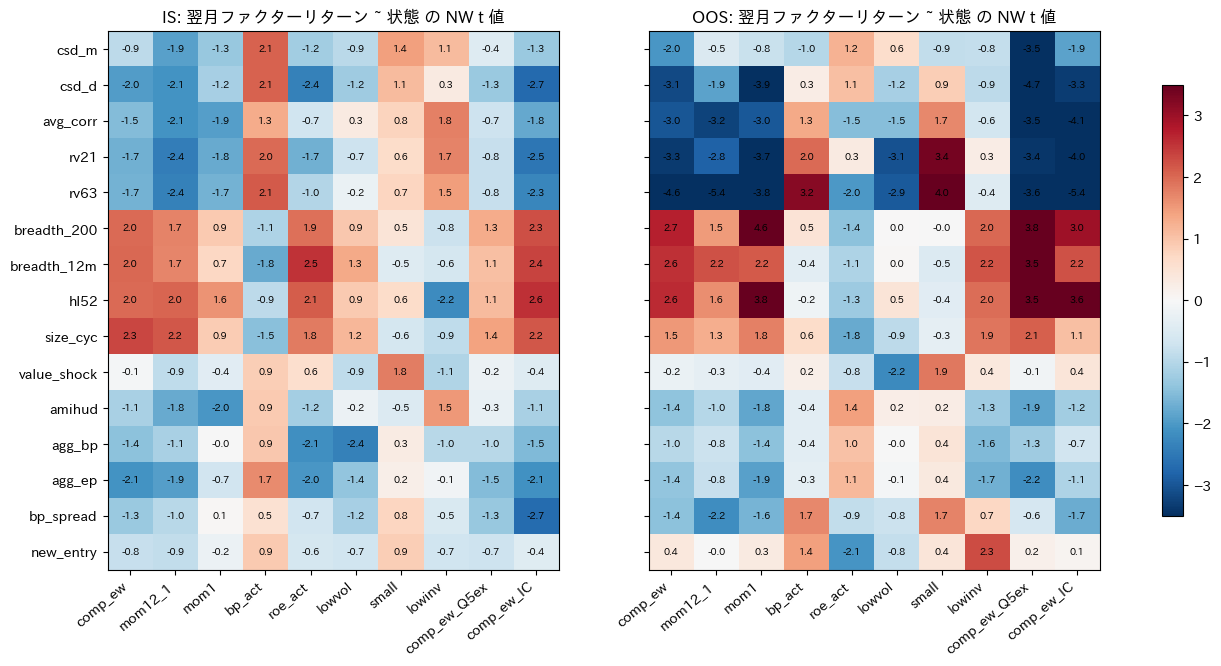

In [14]:
rows = []
for sc in STATE_COLS:
    x = zscore_full(states[sc]).reindex(F.index)
    for fc in FAC_COLS:
        r = {"状態": sc, "ファクター": fc}
        for lab, (a, b) in {
            "全": ("2008-01-31", END),
            "IS": ("2008-01-31", IS_END),
            "OOS": ("2018-01-31", END),
        }.items():
            bb, tt = nw_tstat(F[fc].loc[a:b].to_numpy(), x.loc[a:b].to_numpy(), lags=3)
            r[f"{lab} b"] = bb * (1 if fc == "comp_ew_IC" else 100)
            r[f"{lab} t"] = tt
        rows.append(r)
REG = pd.DataFrame(rows)
robust = REG[
    (REG["IS t"].abs() > 1.5)
    & (REG["OOS t"].abs() > 1.5)
    & (np.sign(REG["IS t"]) == np.sign(REG["OOS t"]))
]
print(
    "頑健な候補（IS・OOS とも |t| > 1.5、同符号）。b は状態 1 SD あたりの翌月リターン（%）、IC は素の値"
)
display(robust.round(2).sort_values("全 t", key=np.abs, ascending=False))
print("全期間 |t| > 2 の組の数:", int((REG["全 t"].abs() > 2).sum()), "/", len(REG))

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, lab in zip(axes, ["IS", "OOS"]):
    t = REG.pivot(index="状態", columns="ファクター", values=f"{lab} t").reindex(
        index=STATE_COLS, columns=FAC_COLS
    )
    im = ax.imshow(t, cmap="RdBu_r", vmin=-3.5, vmax=3.5, aspect="auto")
    ax.set_xticks(range(len(FAC_COLS)), FAC_COLS, rotation=40, ha="right")
    ax.set_yticks(range(len(STATE_COLS)), STATE_COLS)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{lab}: 翌月ファクターリターン ~ 状態 の NW t 値")
    ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### 4.3 散らばりの予測（リスク管理への使い道）

平均（期待リターン）よりも散らばり（リスク）の方が予測しやすいのが通例。翌月のファクターリターンの絶対値 $|F_{t+1}|$ を状態に回帰する。
また `comp_ew` の Q5−Q1 の翌月の実現ボラ（日次ではなく月次の絶対値）と、状態の三分位の関係を見る。

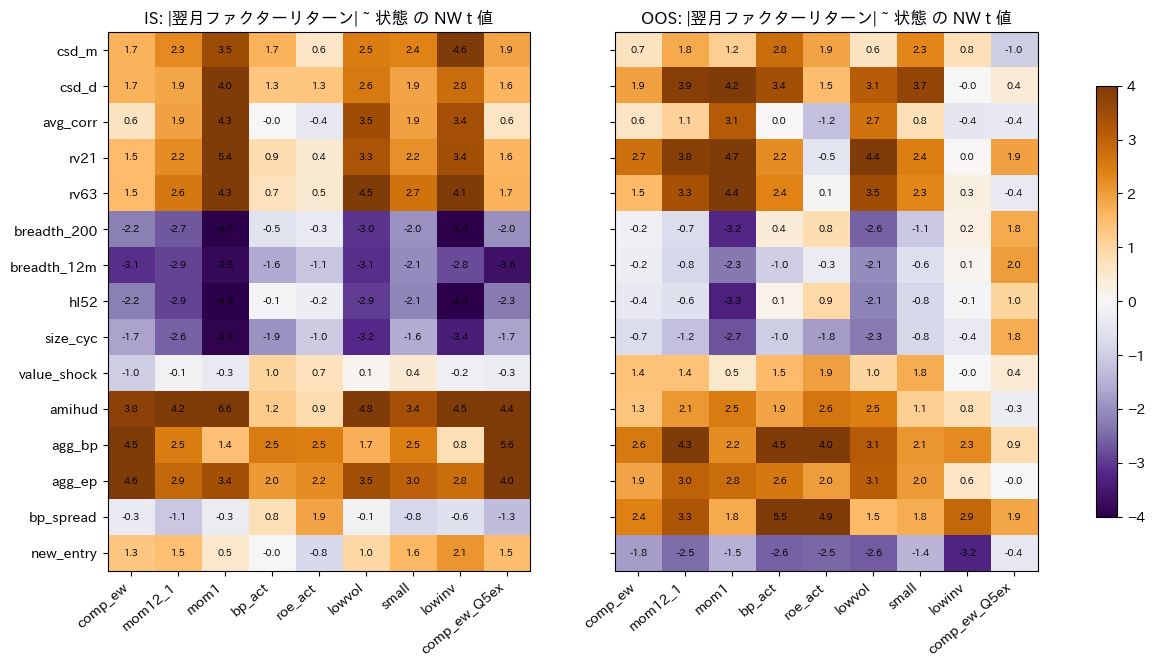

|翌月ファクターリターン| の予測で IS・OOS とも |t| > 2・同符号の組: 34 / 135


状態,agg_bp,agg_ep,amihud,avg_corr,breadth_12m,breadth_200,csd_d,csd_m,hl52,rv21,rv63,size_cyc
組数,5,5,3,2,2,2,2,1,2,4,4,2


In [15]:
rows = []
for sc in STATE_COLS:
    x = zscore_full(states[sc]).reindex(F.index)
    for fc in [c for c in FAC_COLS if c != "comp_ew_IC"]:
        r = {"状態": sc, "ファクター": fc}
        for lab, (a, b) in {
            "IS": ("2008-01-31", IS_END),
            "OOS": ("2018-01-31", END),
        }.items():
            bb, tt = nw_tstat(
                F[fc].abs().loc[a:b].to_numpy(), x.loc[a:b].to_numpy(), lags=3
            )
            r[f"{lab} t"] = tt
        rows.append(r)
ABS = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
cols_abs = [c for c in FAC_COLS if c != "comp_ew_IC"]
for ax, lab in zip(axes, ["IS", "OOS"]):
    t = ABS.pivot(index="状態", columns="ファクター", values=f"{lab} t").reindex(
        index=STATE_COLS, columns=cols_abs
    )
    im = ax.imshow(t, cmap="PuOr_r", vmin=-4, vmax=4, aspect="auto")
    ax.set_xticks(range(len(cols_abs)), cols_abs, rotation=40, ha="right")
    ax.set_yticks(range(len(STATE_COLS)), STATE_COLS)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{lab}: |翌月ファクターリターン| ~ 状態 の NW t 値")
    ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()
rob_abs = ABS[
    (ABS["IS t"].abs() > 2)
    & (ABS["OOS t"].abs() > 2)
    & (np.sign(ABS["IS t"]) == np.sign(ABS["OOS t"]))
]
print(
    "|翌月ファクターリターン| の予測で IS・OOS とも |t| > 2・同符号の組:",
    len(rob_abs),
    "/",
    len(ABS),
)
display(rob_abs.groupby("状態").size().rename("組数").to_frame().T)

In [16]:
# comp_ew Q5−Q1 の三分位別の平均・標準偏差・シャープ（年率）
rows = {}
for sc in [
    "csd_m",
    "avg_corr",
    "rv63",
    "breadth_200",
    "size_cyc",
    "value_shock",
    "bp_spread",
]:
    g = terc[sc].reindex(F.index)
    for k, lab in zip((0, 1, 2), ("低", "中", "高")):
        x = F["comp_ew"][g == k].dropna()
        rows[(sc, lab)] = {
            "月平均(%)": 100 * x.mean(),
            "月 SD(%)": 100 * x.std(),
            "年率 SR": x.mean() / x.std() * np.sqrt(12),
            "月数": len(x),
        }
display(pd.DataFrame(rows).T.round(2))

月平均(%)  月 SD(%)  年率 SR     月数
csd_m       低    2.27     4.03   1.95   82.0
            中    1.37     4.64   1.02   66.0
            高    0.66     4.34   0.52   40.0
avg_corr    低    1.95     4.63   1.46   99.0
            中    2.39     3.47   2.38   57.0
            高   -0.84     4.10  -0.71   32.0
rv63        低    2.36     3.90   2.10  110.0
            中    0.91     4.71   0.67   58.0
            高   -0.48     4.77  -0.35   20.0
breadth_200 低   -0.33     4.96  -0.23   41.0
            中    2.08     4.11   1.75   85.0
            高    2.25     3.90   2.00   62.0
size_cyc    低    1.06     5.27   0.70   48.0
            中    1.66     4.31   1.34   72.0
            高    1.93     3.63   1.85   68.0
value_shock 低    1.67     5.10   1.13   43.0
            中    1.71     4.08   1.45   66.0
            高    1.49     4.16   1.24   79.0
bp_spread   低    1.17     2.74   1.48   35.0
            中    2.17     2.96   2.53   73.0
            高    1.29     5.74   0.78   80.0

## 5. 頑健そうな組み合わせの確認

4.2 の頑健な候補と、仮説 H1〜H5 に対応する組について、状態で翌月のファクター成績を分けた累積図を描く
（各月を「前月末の状態が高い三分位」「それ以外」に分け、それぞれの月だけを足し上げる）。

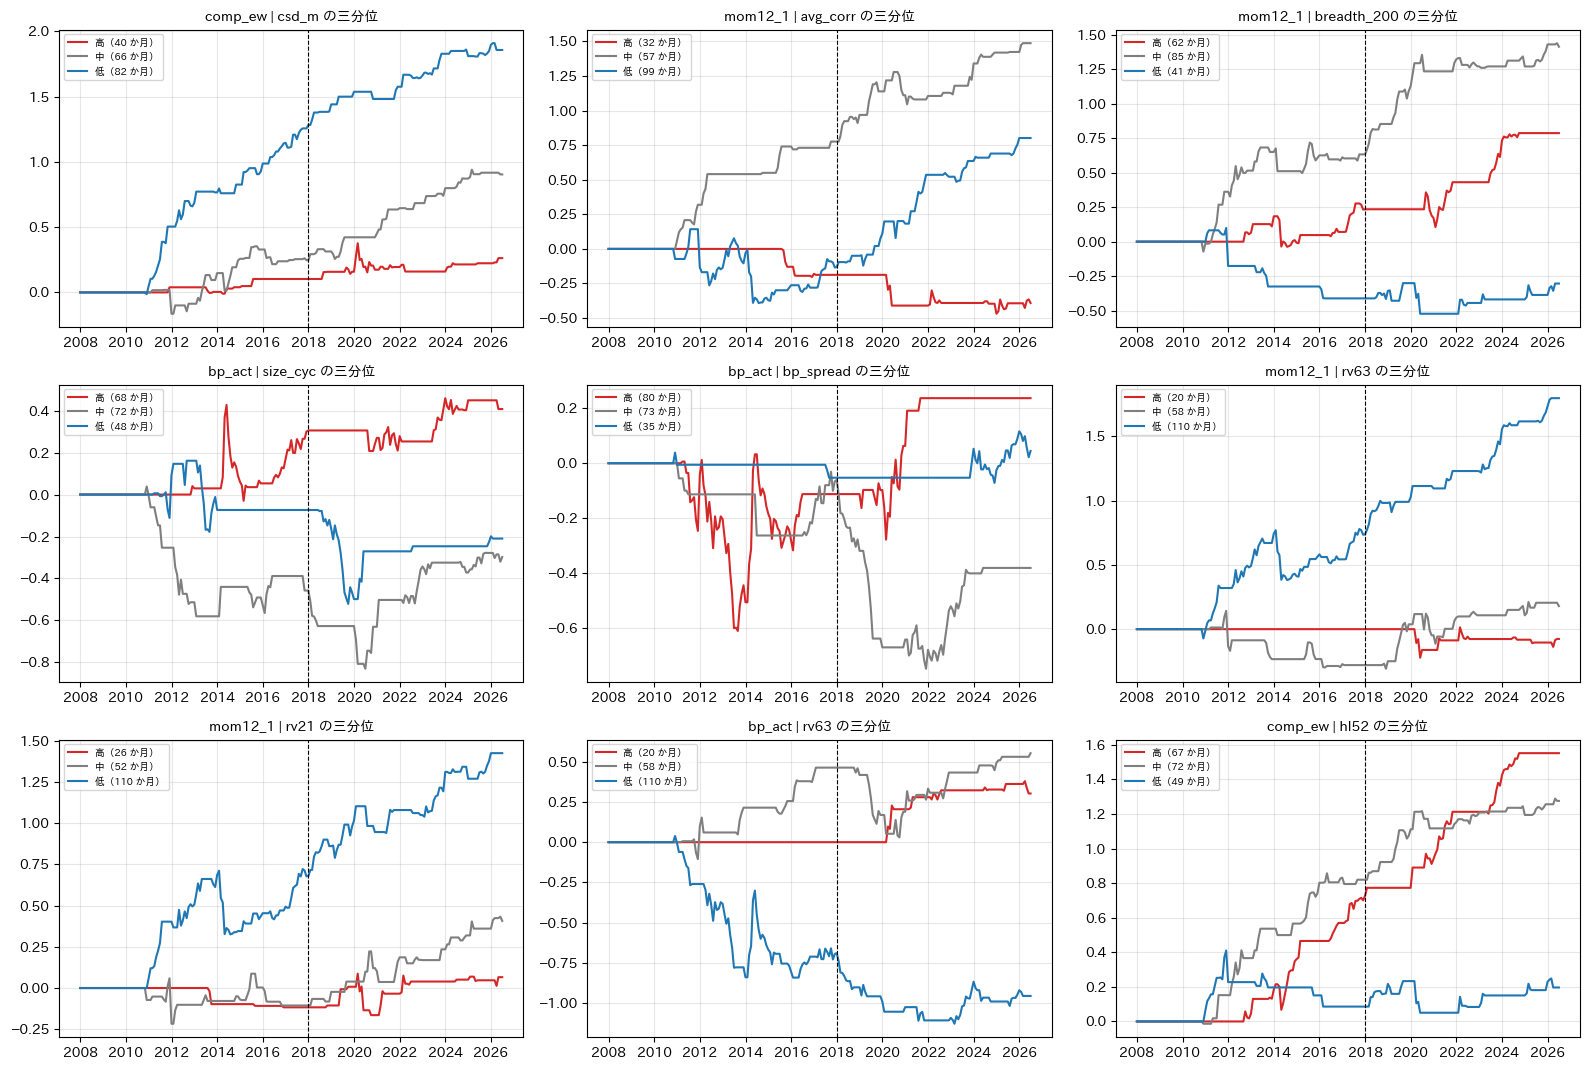

In [17]:
CHECK = [
    ("csd_m", "comp_ew"),  # H1
    ("avg_corr", "mom12_1"),  # H2
    ("breadth_200", "mom12_1"),  # H2
    ("size_cyc", "bp_act"),  # H3
    ("bp_spread", "bp_act"),  # H5
]
extra = [
    (r["状態"], r["ファクター"])
    for _, r in robust.sort_values("全 t", key=np.abs, ascending=False).iterrows()
    if (r["状態"], r["ファクター"]) not in CHECK and r["ファクター"] != "comp_ew_IC"
][:4]
CHECK += extra
fig, axes = plt.subplots(
    int(np.ceil(len(CHECK) / 3)), 3, figsize=(16, 3.6 * int(np.ceil(len(CHECK) / 3)))
)
for ax, (sc, fc) in zip(axes.ravel(), CHECK):
    g = terc[sc].reindex(F.index)
    f = F[fc]
    for k, lab, col in [(2, "高", "C3"), (1, "中", "C7"), (0, "低", "C0")]:
        ax.plot(
            f.index,
            f.where(g == k).fillna(0).cumsum(),
            color=col,
            label=f"{lab}（{int((g == k).sum())} か月）",
        )
    ax.axvline(pd.Timestamp("2018-01-01"), color="k", linestyle="--", linewidth=0.8)
    ax.set_title(f"{fc} | {sc} の三分位", fontsize=10)
    ax.legend(fontsize=7)
for ax in axes.ravel()[len(CHECK) :]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. 頑健性: 危機の月を除く・翌月の市場の向き

ストレス状態（高ボラ・高相関・低ブレス）で `comp_ew` が弱いのは、2009 年や 2020 年のような少数の「暴落後の反発」だけで決まっていないか。
(a) 2008-09〜2009-12 と 2020-02〜2020-12 を除いて 4.2 の回帰をやり直す。(b) 前月末の状態（`rv63` が高い三分位か）と、当月の市場の上げ下げで 4 区分にする。

In [18]:
excl = (F.index >= "2008-08-31") & (F.index <= "2009-11-30") | (
    F.index >= "2020-01-31"
) & (F.index <= "2020-11-30")
rows = []
for sc in [
    "rv63",
    "rv21",
    "avg_corr",
    "csd_d",
    "breadth_200",
    "breadth_12m",
    "hl52",
    "size_cyc",
]:
    x = zscore_full(states[sc]).reindex(F.index)
    for fc in ["comp_ew", "comp_ew_Q5ex", "comp_ew_IC", "mom12_1", "bp_act", "small"]:
        y = F[fc]
        b0, t0 = nw_tstat(y.to_numpy(), x.to_numpy(), lags=3)
        b1, t1 = nw_tstat(y[~excl].to_numpy(), x[~excl].to_numpy(), lags=3)
        k = 1 if fc == "comp_ew_IC" else 100
        rows.append(
            {
                "状態": sc,
                "ファクター": fc,
                "全 b": k * b0,
                "全 t": t0,
                "危機除外 b": k * b1,
                "危機除外 t": t1,
            }
        )
display(
    pd.DataFrame(rows)
    .pivot(index="状態", columns="ファクター", values="危機除外 t")
    .round(2)
)
print(
    "上表: 危機の月（行 = スコアの月末で 2008-08〜2009-11、2020-01〜2020-11、計",
    int(excl.sum()),
    "か月）を除いた NW t 値",
)

ファクター,bp_act,comp_ew,comp_ew_IC,comp_ew_Q5ex,mom12_1,small
状態,,,,,,
avg_corr,0.02,-2.20,-2.06,-2.24,-2.59,0.94
breadth_12m,-0.29,2.44,2.07,2.06,1.38,0.54
breadth_200,0.23,2.82,2.79,2.48,1.49,0.99
csd_d,0.39,-3.08,-2.80,-3.38,-3.98,-0.24
hl52,0.15,2.85,3.13,2.48,1.64,0.71
rv21,0.47,-1.71,-1.71,-1.42,-2.90,0.09
rv63,0.72,-2.49,-2.32,-2.51,-3.96,0.98
size_cyc,-0.05,2.32,1.51,1.88,1.60,0.42


上表: 危機の月（行 = スコアの月末で 2008-08〜2009-11、2020-01〜2020-11、計 27 か月）を除いた NW t 値


In [19]:
mkt_next = idx_m["cw_imi"].shift(-1).reindex(F.index)  # 行 t = 月 t+1 の市場
rows = {}
for sc in ["rv63", "avg_corr", "breadth_200"]:
    g = terc[sc].reindex(F.index)
    stress = (g == 2) if sc != "breadth_200" else (g == 0)
    for st_lab, st in [("ストレス", stress), ("平常", ~stress & g.notna())]:
        for up_lab, up in [("市場↑", mkt_next > 0), ("市場↓", mkt_next <= 0)]:
            m = st & up
            rows[(sc, st_lab, up_lab)] = {
                "comp_ew Q5−Q1": 100 * F["comp_ew"][m].mean(),
                "mom12_1": 100 * F["mom12_1"][m].mean(),
                "bp_act": 100 * F["bp_act"][m].mean(),
                "small": 100 * F["small"][m].mean(),
                "市場": 100 * mkt_next[m].mean(),
                "月数": int(m.sum()),
            }
print(
    "前月末の状態 × 当月の市場の向き（%/月）。ストレス = rv63・avg_corr の高い三分位、breadth_200 の低い三分位"
)
display(pd.DataFrame(rows).T.round(2))

前月末の状態 × 当月の市場の向き（%/月）。ストレス = rv63・avg_corr の高い三分位、breadth_200 の低い三分位


comp_ew Q5−Q1  mom12_1  bp_act  small    市場     月数
rv63        ストレス 市場↑          -0.28    -0.09    1.98   3.37  5.36   16.0
                 市場↓          -1.29    -1.52   -0.37  -0.12 -3.05    4.0
            平常   市場↑           0.69     0.11    1.46   0.44  3.51  102.0
                 市場↓           3.66     2.82   -2.86  -1.74 -3.72   66.0
avg_corr    ストレス 市場↑          -1.07    -1.28    2.63   3.05  4.94   21.0
                 市場↓          -0.39    -1.12    0.64  -0.64 -3.15   11.0
            平常   市場↑           0.91     0.38    1.29   0.36  3.50   97.0
                 市場↓           4.08     3.26   -3.35  -1.84 -3.78   59.0
breadth_200 ストレス 市場↑          -1.16    -1.61    2.37   1.58  5.42   27.0
                 市場↓           1.26     0.93   -2.79  -2.07 -4.12   14.0
            平常   市場↑           1.07     0.58    1.28   0.61  3.26   91.0
                 市場↓           3.91     2.98   -2.70  -1.54 -3.57   56.0

## 7. 事前に決めたルールでの試算（パラメータ探索なし）

状態から `comp_ew` のロングショートの量を変える単純なルール。いずれも月末 $t$ の情報だけで $t+1$ の量を決める。

- `vol_scaled`: 量 $= \overline{rv63} / rv63_t$（$\overline{rv63}$ は $t$ までの拡大窓平均、上限 2）。Moreira–Muir 型
- `stress_half`: `rv63` が拡大窓の高い三分位なら 0.5、それ以外は 1
- `breadth_half`: `breadth_200` が低い三分位なら 0.5、それ以外は 1

平均量が違うと比較できないので、シャープレシオ（年率）と、各ルールの量を全期間で平均 1 に揃えたときの月平均を見る（後者は事後の正規化なので参考）。

全 SR  IS SR  OOS SR   平均量  量を平均1にした月平均(%)
comp_ew      static        1.27   1.30    1.27  1.00            1.60
             vol_scaled    1.46   1.39    1.66  1.50            1.86
             stress_half   1.36   1.30    1.50  0.95            1.72
             breadth_half  1.47   1.54    1.45  0.89            1.84
comp_ew_Q5ex static        1.58   1.77    1.41  1.00            0.87
             vol_scaled    1.72   1.78    1.70  1.50            0.98
             stress_half   1.66   1.77    1.58  0.95            0.92
             breadth_half  1.72   1.96    1.51  0.89            0.97
mom12_1      static        0.65   0.32    0.99  1.00            1.03
             vol_scaled    0.81   0.40    1.39  1.50            1.28
             stress_half   0.70   0.32    1.14  0.95            1.11
             breadth_half  0.81   0.53    1.11  0.89            1.25

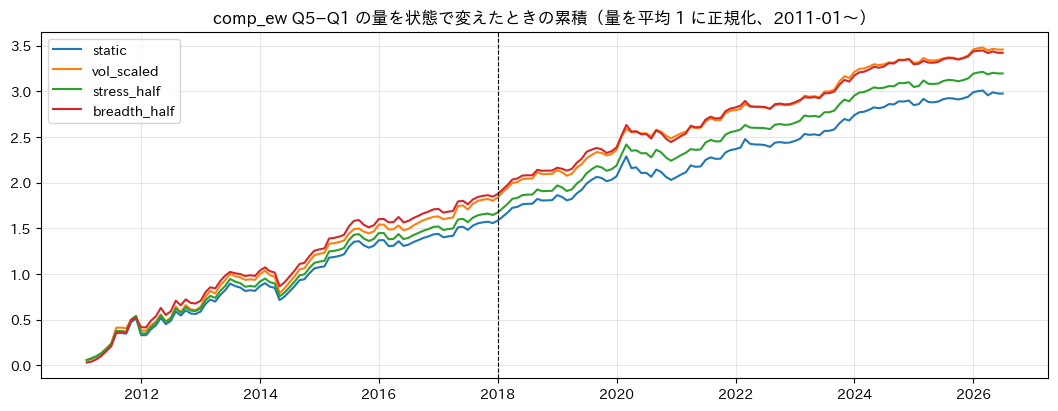

In [20]:
rv = states["rv63"]
w_vol = (rv.expanding(36).mean() / rv).clip(upper=2.0)
w_stress = pd.Series(np.where(terc["rv63"] == 2, 0.5, 1.0), index=terc.index).where(
    terc["rv63"].notna()
)
w_breadth = pd.Series(
    np.where(terc["breadth_200"] == 0, 0.5, 1.0), index=terc.index
).where(terc["breadth_200"].notna())
rules = {
    "static": pd.Series(1.0, index=states.index),
    "vol_scaled": w_vol,
    "stress_half": w_stress,
    "breadth_half": w_breadth,
}
rows = {}
cum = {}
for fc in ["comp_ew", "comp_ew_Q5ex", "mom12_1"]:
    for rn, w in rules.items():
        w = w.reindex(F.index)
        r = (w * F[fc]).dropna()
        r = r.loc["2011-01-31":]  # 判定に 36 か月必要なので比較期間を揃える
        out = {}
        for lab, (a, b) in {
            "全": ("2011-01-31", END),
            "IS": ("2011-01-31", IS_END),
            "OOS": ("2018-01-31", END),
        }.items():
            x = r.loc[a:b]
            out[f"{lab} SR"] = x.mean() / x.std() * np.sqrt(12)
        out["平均量"] = w.loc[r.index].mean()
        out["量を平均1にした月平均(%)"] = 100 * r.mean() / out["平均量"]
        rows[(fc, rn)] = out
        if fc == "comp_ew":
            cum[rn] = (r / out["平均量"]).cumsum()
display(pd.DataFrame(rows).T.round(2))

fig, ax = plt.subplots(figsize=(13, 4.5))
for rn, c in cum.items():
    ax.plot(c.index, c, label=rn)
ax.axvline(pd.Timestamp("2018-01-01"), color="k", linestyle="--", linewidth=0.8)
ax.legend()
ax.set_title(
    "comp_ew Q5−Q1 の量を状態で変えたときの累積（量を平均 1 に正規化、2011-01〜）"
)
plt.show()

## 所見

**結論: 状態変数で市場そのもの（時価加重・サイズサイクル）はほとんど予測できない。一方、「ストレス状態」（高ボラ・高い平均相関・高い横断面分散・低いブレス）の翌月は `comp_ew` とモメンタムが明確に弱く、
IS（2008〜2017）・OOS（2018〜）の両方で、危機の月を除いても残る。予測できるのは市場の方向ではなく「クロスセクショナルなスコアがいつ効きにくいか」。**

1. **状態変数の性質**: 状態は大きく 3 群に分かれる。(a) ストレス群（`rv21`・`rv63`・`avg_corr`・`csd_m`・`csd_d`、GFC と COVID で z 値 +1.5〜+2.7）、
   (b) ブレス群（`breadth_200`・`breadth_12m`・`hl52`・`size_cyc`、GFC・2011・テーパー・2018–19 で z 値 −0.6〜−1.6）、(c) 水準群（`agg_bp`・`agg_ep`・`bp_spread`・`amihud`、自己相関 0.9 以上でトレンドを持つ）。
   流動性は改善が続き（Amihud 中央値は 2008 年から対数で約 −1.5）、BP スプレッドは 2015 年頃の 3.0 から足元 2.2 へ縮小、市場の B/P は 2022 年以降で最も割高な水準。
   平均ペア相関は 2008〜09 の 0.4〜0.5 から平常時 0.15〜0.25 に下がったが、2020・2022・2025 年に一時 0.35 前後まで上がった。
2. **市場の予測は弱い（H4 はほぼ不支持）**: 翌 1 か月の時価加重リターンで NW |t| > 2 は `agg_bp`（+1.08%/SD、t 2.05）と `value_shock`（+0.84%、t 2.09）だけで、
   `agg_bp` は IS t 2.44 → OOS t 0.91 と弱まる。サンプル外 R²（2013 年以降）は 1・3・12 か月のほぼすべてで負（最良でも +0.02）で、過去平均に勝てない。
   12 か月先で `agg_bp`（t 2.9）・`agg_ep`（t 3.1）が有意に見えるのは重複期間と高い持続性による見かけの効果（Stambaugh バイアス）で、R²_OS は −0.5〜−0.9。
   IPO 活動（`new_entry`）が高いと市場が弱いように見えたのは 2007 年のユニバース拡大による見かけで、その期間を除くと消えた（1 か月 t 0.56）。
3. **サイズサイクル（EW−CW）**: 売買代金のショック（`value_shock`）が高い翌月は EW−CW が +0.43%/SD（t 2.36、IS 1.51 / OOS 2.11、R²_OS +0.02）。
   ファクター側でも小型（`small` の Q5−Q1）が +0.85%/SD（IS t 1.79 / OOS 1.86）。出来高の膨らんだ月の後に小型株が続伸する方向で、「過熱 → 反転」の予測（H4）とは逆。弱いが両期間で同符号。
4. **ストレス状態では `comp_ew` が効かない（中心の結果）**: 前月末の状態の三分位で翌月の `comp_ew` Q5−Q1 を分けると、`rv63` 低 2.36% / 中 0.91% / 高 −0.48%（差の t −2.5）、
   `avg_corr` 低 1.95% / 高 −0.84%（t −3.2）、`breadth_200` 低 −0.33% / 高 2.25%（t 2.8）。IC も `avg_corr` 高で −0.016（低 0.077、t −4.1）、`rv63` 高で −0.001（低 0.093、t −3.4）。
   連続値の回帰では `comp_ew` の IC に対し `hl52` +0.03/SD（IS t 2.55 / OOS 3.57）、`breadth_200`（2.26 / 2.96）、`csd_d` −0.03（−2.73 / −3.32）、`rv63` −0.02（−2.29 / −5.38）、`avg_corr`（−1.79 / −4.07）。
   **ロングオンリーの代理（Q5 − ユニバース等ウェイト）でも同じ**: `csd_m` 低 1.24% / 高 0.28%（t −2.9）、`avg_corr` 低 1.09% / 高 −0.06%（t −3.2）、`breadth_200` 低 0.08% / 高 1.15%（t 2.7）。
5. **危機の月を除いても残る**: 2008-08〜2009-11 と 2020-01〜2020-11（27 か月）を除いても、`comp_ew` の t 値は `csd_d` −3.1、`hl52` +2.9、`breadth_200` +2.8、`rv63` −2.5、`avg_corr` −2.2。
   モメンタム（`mom12_1`）は `rv63` −4.0、`csd_d` −4.0、`rv21` −2.9、`avg_corr` −2.6。少数の暴落後反発だけで決まっている結果ではない。
6. **仕組みは「ストレス後の反発で負ける」**: `rv63` がストレス状態の月に市場が上がると `comp_ew` Q5−Q1 は −0.28%（平常時 × 上昇 +0.69%）、`avg_corr` では −1.07%（+0.91%）、`breadth_200` では −1.16%（+1.07%）。
   このとき `bp_act` は +2.0〜2.6%、小型は +1.6〜3.4% と大きく勝つ。平常時の `comp_ew` は下落月に +3.7〜4.1% と強く、**`comp_ew` のロングショートは「短ベータ・短ジャンク」**。
   ストレス後は反発の確率と幅が大きい（ストレス × 上昇の市場平均 +4.9〜5.4%）ので、期待値がマイナスになる。`momentum_regime` の「弱気局面 × 上昇月で負ける」と同じ現象を、24 か月リターンより早く反応する変数で捉えている。
7. **バリュー・小型はストレス後に強い（H3 は形を変えて成立）**: `rv63` → `bp_act` は +1.07%/SD（IS t 2.14 / OOS 3.18）、`rv63` 高の三分位で `small` 2.67%（低 −0.76%、t 2.7）、`lowvol` −2.84%（低 1.23%、t −2.5）。
   一方、サイズサイクル（`size_cyc`）の水準はバリューを予測しない（t 0.9）。`size_cyc` が高い（小型優位）と `comp_ew` はむしろ良い（+0.86%/SD、IS 2.33 / OOS 1.52）。
8. **仮説 H1・H5 は不支持**: 横断面の分散が高いとスプレッドが大きくなるのではなく、逆に `comp_ew` は弱くなる（分散はストレスの別の顔）。
   バリュー・スプレッド（`bp_spread`）は `bp_act` を予測せず（三分位差 t 0.17）、むしろ `comp_ew` の IC と負の関係（−3.07）。
9. **散らばり（リスク）は予測しやすい**: |翌月ファクターリターン| の予測では、IS・OOS とも |t| > 2・同符号の組が 34 / 135（ボラ・相関・バリュエーション群）。期待リターンより安定して予測できる。
10. **事前に決めた単純なルールの試算**（2011〜、パラメータ探索なし）: `comp_ew` Q5−Q1 のシャープレシオは静的 1.27 に対し、`vol_scaled`（$\overline{rv63}/rv63$、上限 2）1.46（IS 1.39 / OOS 1.66）、
    `breadth_half`（ブレス低い三分位で半分）1.47（1.54 / 1.45）、`stress_half` 1.36。Q5 − ユニバースでも 1.58 → 1.72。モメンタムは 0.65 → 0.81。どのルールも両期間で静的を上回る。
11. **多重検定**: 状態 × ファクターの 150 組のうち全期間 |t| > 2 は 43 組で、偶然の期待値（約 7）を大きく超える。ただし状態は 3 群に強く相関しているので、実質の独立な発見は「ストレス群・ブレス群 → `comp_ew`・モメンタム」「ストレス → バリュー・小型」の 2〜3 個と数えるべき。

**含意**

- 時系列の状態は、市場の方向を当てる用途（タイミング）にはほぼ使えないが、**クロスセクショナルなスコアの「効き具合」の予測には使える**。ストレス状態では、スコアのアクティブリスクを落とす（TE 目標を下げる、ベータ・サイズを中立化する）のが合理的。
- 弱気局面でモメンタムを外す試み（`momentum_regime`）が合成スコアを改善しなかったのは、外す対象（モメンタムだけ）と判定（24 か月リターン）がずれていたため。
  負けているのは `comp_ew` 全体で、判定は直近の実現ボラ・相関・ブレスの方が早く、危機を除いても効く。外すより「量（アクティブリスク）を減らす」形の方が、ロングオンリーで回転率も増やさずに実装できる。
- ストレス後に勝つのはバリュー・小型・高ボラ（ジャンクの反発）。`comp_ew` に、ストレス時だけベータ・`RESVOL`・`LIQUIDTY` を中立化する制約（`momentum_regime` の含意と同じ）を入れる、という手当ての根拠が一段強くなった。

**次の候補（アイディア）**

1. **状態依存のアクティブリスク（最有力）**: bax の TE 目標やリスク回避度を `rv63`・`avg_corr`・`breadth_200` の拡大窓パーセンタイルで連続的に変える（例: 量 $\propto \overline{rv63}/rv63$）。
   税引後・回転率込みで、静的 TE との比較を bax で検証する。量の変更は回転率をあまり増やさない点がインドの STCG 環境で有利。
2. **ストレス時のリスク中立化**: ストレス状態の月だけ BETA・RESVOL・LIQUIDTY・SIZE のアクティブエクスポージャー上限を絞る。6 の「ストレス × 上昇月」の負けを直接減らせるかを見る。
3. **状態に応じたスリーブ配分**: ストレス時にモメンタムの比率を下げ、バリュー（業種間の BP）を上げる。ただし `momentum_regime` の結果から、ロングオンリーの Q5 では効果が小さい可能性が高いので、1・2 より優先度は低い。
4. **出来高ショック → 小型の続伸**: `value_shock` は EW−CW と小型ファクターを両期間で同符号に予測した（t 1.8〜2.4）。根拠は弱いが既存研究と重ならないので、銘柄レベル（業種・銘柄の売買代金ショック）に落として確認する価値はある。
5. 注意: 市場の方向の予測（バリュエーション、IPO 活動など）はサンプル外で過去平均に勝てないので、追わない。